# Variables aleatorias discretas y continuas: probabilidad, densidad y momentos

Desarrollo de los ejercicios sobre variables aleatorias discretas y continuas, funciones de
probabilidad y de densidad, funciones de acumulación, esperanza y varianza con sus propiedades, y
acotaciones por el teorema de Chebyshev. Los valores analíticos se derivan en cada sección; en
Python se verifican por enumeración del espacio muestral, cuadratura numérica (regla del trapecio)
para las integrales de densidad y momentos, y simulación Monte Carlo con semilla fija para las
funciones de probabilidad.

## Marco teórico

### Variable aleatoria y función de probabilidad

Una variable aleatoria discreta $X$ asigna a cada resultado del espacio muestral un valor real,
tomando un conjunto de valores $D$ (dominio) finito o numerable. Su función de probabilidad es
$p(x) = P(X = x)$ y debe cumplir:

$$p(x) \ge 0 \ \ \forall x \in D, \qquad \sum_{x \in D} p(x) = 1$$

Con ambas condiciones, $P(X \in A) = \sum_{x \in A} p(x)$ define una probabilidad consistente
sobre el dominio.

### Esperanza y varianza de una variable discreta

$$E[X] = \mu = \sum_{x \in D} x\, p(x), \qquad E[g(X)] = \sum_{x \in D} g(x)\, p(x)$$

$$Var(X) = E[(X - \mu)^2] = E[X^2] - (E[X])^2, \qquad \sigma = \sqrt{Var(X)}$$

Propiedades que se usan en los ejercicios:

$$E[aX + b] = a\,E[X] + b, \qquad Var(aX + b) = a^2\,Var(X), \qquad Var(c) = 0$$

La esperanza es lineal; la varianza escala con el cuadrado del coeficiente y no depende del
desplazamiento.

### Densidad y función de acumulación de una variable continua

Una variable aleatoria continua tiene densidad $f(x) \ge 0$ con

$$\int_{-\infty}^{+\infty} f(x)\,dx = 1$$

y función de acumulación

$$F(x) = P(X \le x) = \int_{-\infty}^{x} f(t)\,dt$$

$F$ es monótona no decreciente, con $\lim_{x\to-\infty} F(x) = 0$ y $\lim_{x\to+\infty} F(x) = 1$.
Donde $F$ es diferenciable, $f(x) = F'(x)$. Para un intervalo,

$$P(a \le X \le b) = F(b) - F(a) = \int_a^b f(x)\,dx, \qquad P(X = c) = 0$$

Los momentos de una continua son integrales:

$$E[X] = \int x\,f(x)\,dx, \qquad E[X^2] = \int x^2 f(x)\,dx, \qquad Var(X) = E[X^2] - (E[X])^2$$

### Teorema de Chebyshev

Para cualquier variable aleatoria con media $\mu$ y varianza $\sigma^2$ finita y $\sigma > 0$, sin
suponer forma de distribución:

$$P(|X - \mu| \ge k\sigma) \le \frac{1}{k^2} \qquad \Longleftrightarrow \qquad P(|X - \mu| < k\sigma) \ge 1 - \frac{1}{k^2}$$

Supuestos: varianza finita y positiva; la desigualdad entrega una cota, no un valor exacto, y vale
para toda distribución (no requiere conocer su forma).

In [1]:
import itertools
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

print("numpy", np.__version__, "| matplotlib", mpl.__version__)

numpy 2.5.4 | matplotlib 3.11.2


## 1. Muestra de tres artículos con reposición de un lote con 10% de defectuosos

Cada artículo extraído se clasifica como $D$ (defectuoso) o $C$ (conforme), con
$P(D) = 0.10$ y $P(C) = 0.90$. La reposición restituye el lote, de modo que las tres extracciones
son ensayos independientes con la misma probabilidad de defecto.

### a) Espacio muestral por extensión

El espacio muestral de la muestra (tres extracciones) tiene $2^3 = 8$ resultados:

| # | Resultado | $P$ |
|---|---|---|
| 1 | DDD | $0.10^3 = 0.0010$ |
| 2 | DDC | $0.10^2 \cdot 0.90 = 0.0090$ |
| 3 | DCD | $0.0090$ |
| 4 | CDD | $0.0090$ |
| 5 | DCC | $0.10 \cdot 0.90^2 = 0.0810$ |
| 6 | CDC | $0.0810$ |
| 7 | CCD | $0.0810$ |
| 8 | CCC | $0.90^3 = 0.7290$ |

Supuestos: reposición (independencia entre extracciones y probabilidad constante), lote lo
suficientemente grande como para que extraer no altere la proporción de defectuosos, y clasificación
dicotómica de cada artículo.

In [2]:
p_D, p_C = 0.10, 0.90

muestra = list(itertools.product("DC", repeat=3))


def prob(seq):
    """P de una secuencia: 0.10^#D * 0.90^#C."""
    return p_D ** seq.count("D") * p_C ** seq.count("C")


print("espacio muestral por extensión:")
for i, seq in enumerate(muestra, start=1):
    print(f"  {i}. {''.join(seq)}   P = {prob(seq):.4f}")
print("suma de probabilidades:", round(sum(prob(s) for s in muestra), 12))

espacio muestral por extensión:
  1. DDD   P = 0.0010
  2. DDC   P = 0.0090
  3. DCD   P = 0.0090
  4. DCC   P = 0.0810
  5. CDD   P = 0.0090
  6. CDC   P = 0.0810
  7. CCD   P = 0.0810
  8. CCC   P = 0.7290
suma de probabilidades: 1.0


### b) Diagrama de árbol

Tres niveles, uno por extracción; en cada nodo las dos ramas posibles llevan $P(D) = 0.10$ y
$P(C) = 0.90$. El producto a lo largo de cada rama da la probabilidad conjunta de la hoja, y la
suma de las ocho hojas es 1.

### c) Variable $X$: número de artículos con defecto

El dominio es $D_X = \{0, 1, 2, 3\}$. Agrupando las secuencias por cantidad de defectos:

$$p(0) = P(CCC) = 0.7290$$

$$p(1) = 3 \cdot (0.10 \cdot 0.90^2) = 0.2430$$

$$p(2) = 3 \cdot (0.10^2 \cdot 0.90) = 0.0270$$

$$p(3) = P(DDD) = 0.0010$$

Verificación de que es función de probabilidad: $p(k) \ge 0$ para todo $k$ del dominio y
$\sum_{k=0}^{3} p(k) = 0.7290 + 0.2430 + 0.0270 + 0.0010 = 1$. Los valores coinciden con la
binomial $p(k) = C(3,k)\,0.10^k\,0.90^{3-k}$, porque la reposición garantiza ensayos independientes
con probabilidad constante.

In [3]:
dominio = sorted({seq.count("D") for seq in muestra})
pmf1 = {k: sum(prob(s) for s in muestra if s.count("D") == k) for k in dominio}
binom = {k: math.comb(3, k) * p_D ** k * p_C ** (3 - k) for k in dominio}

print(f"{'k':>3}{'p(k)':>10}{'binomial':>12}")
for k in dominio:
    print(f"{k:>3}{pmf1[k]:>10.4f}{binom[k]:>12.4f}")
print("dominio:", dominio)
print("p(k) >= 0:", all(v >= 0 for v in pmf1.values()))
print("suma p(k):", round(sum(pmf1.values()), 12))

# verificación por simulación
rng = np.random.default_rng(5)
n_sim = 100_000
X_sim = (rng.random((n_sim, 3)) < p_D).sum(axis=1)
frec = np.bincount(X_sim, minlength=4) / n_sim

print("\nk        :", dominio)
print("exacta   :", np.round([pmf1[k] for k in dominio], 4))
print("simulada :", np.round(frec, 4))

  k      p(k)    binomial
  0    0.7290      0.7290
  1    0.2430      0.2430
  2    0.0270      0.0270
  3    0.0010      0.0010
dominio: [0, 1, 2, 3]
p(k) >= 0: True
suma p(k): 1.0

k        : [0, 1, 2, 3]
exacta   : [0.729 0.243 0.027 0.001]
simulada : [0.7297 0.2413 0.0281 0.0008]


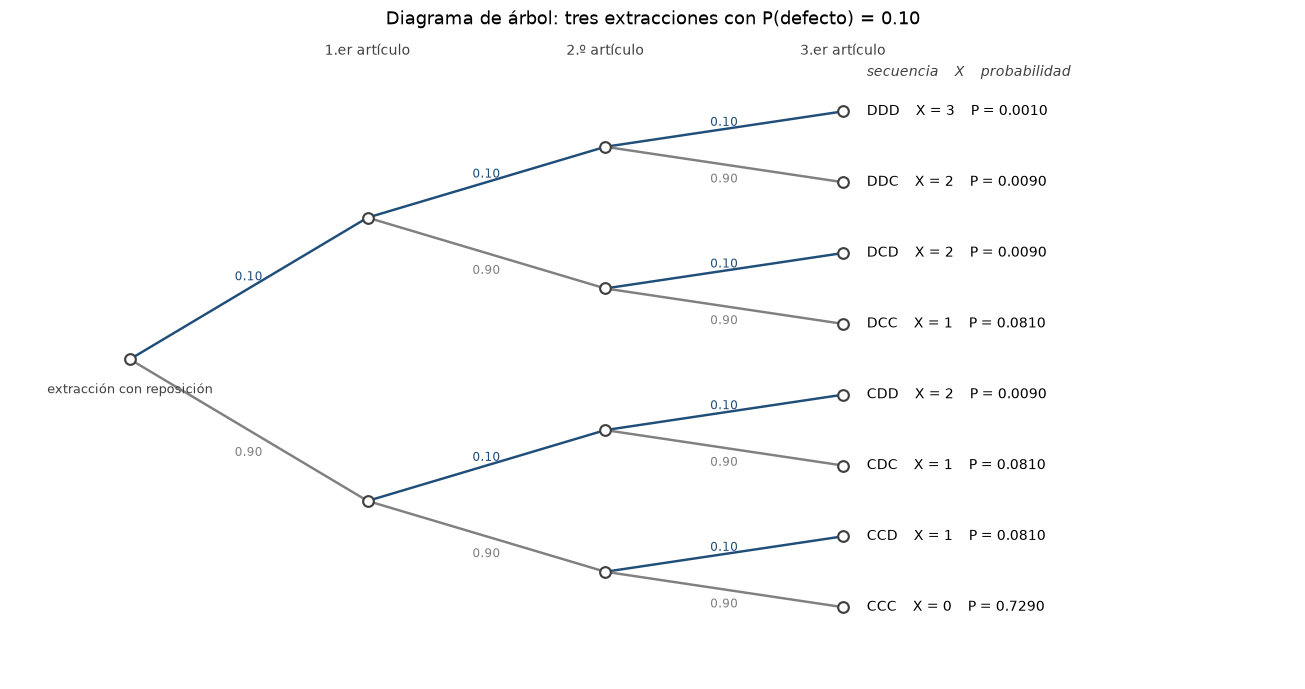

In [4]:
fig, ax = plt.subplots(figsize=(12, 6.4))
ax.axis("off")
ax.set_xlim(-0.5, 4.9)
ax.set_ylim(-4.5, 4.6)


def rama(x0, y0, x1, y1, etiqueta, color, dy=0.0):
    ax.plot([x0, x1], [y0, y1], color=color, linewidth=1.6, zorder=1)
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + dy, etiqueta, fontsize=8,
            color=color, ha="center", va="center")


def nodo(x, y):
    ax.plot(x, y, "o", markersize=7, color="white", markeredgecolor="#404040",
            markeredgewidth=1.4, zorder=3)


hojas_y = [3.5 - i for i in range(8)]
secuencias = ["".join(p) for p in itertools.product("DC", repeat=3)]

nodo(0, 0)
for y in (2.0, -2.0):
    nodo(1, y)
for y in (3.0, 1.0, -1.0, -3.0):
    nodo(2, y)
for y in hojas_y:
    nodo(3, y)

# nivel 1
rama(0, 0, 1, 2, "0.10", AZUL, dy=0.16)
rama(0, 0, 1, -2, "0.90", GRIS, dy=-0.32)
# nivel 2
rama(1, 2, 2, 3.0, "0.10", AZUL, dy=0.11)
rama(1, 2, 2, 1.0, "0.90", GRIS, dy=-0.25)
rama(1, -2, 2, -1.0, "0.10", AZUL, dy=0.11)
rama(1, -2, 2, -3.0, "0.90", GRIS, dy=-0.25)
# nivel 3
for y in (3.0, 1.0, -1.0, -3.0):
    rama(2, y, 3, y + 0.5, "0.10", AZUL, dy=0.09)
    rama(2, y, 3, y - 0.5, "0.90", GRIS, dy=-0.21)

for y, seq in zip(hojas_y, secuencias):
    ax.text(3.1, y, f"{seq}    X = {seq.count('D')}    P = {prob(seq):.4f}",
            fontsize=9, va="center")

ax.text(0, -0.48, "extracción con reposición", fontsize=8.5, ha="center", color="#404040")
for x, texto in ((1, "1.er artículo"), (2, "2.º artículo"), (3, "3.er artículo")):
    ax.text(x, 4.3, texto, fontsize=9, ha="center", color="#404040")
ax.text(3.1, 4.0, "secuencia    X    probabilidad", fontsize=9, ha="left",
        color="#404040", style="italic")
ax.set_title("Diagrama de árbol: tres extracciones con P(defecto) = 0.10")
plt.tight_layout()
plt.show()

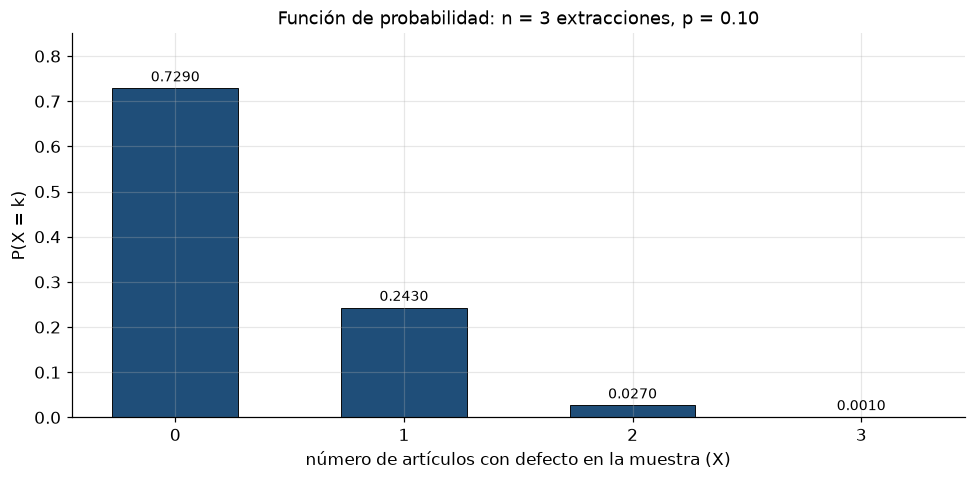

In [5]:
k1 = np.array(sorted(pmf1))
p1 = np.array([pmf1[k] for k in k1])

fig, ax = plt.subplots()
ax.bar(k1, p1, width=0.55, color=AZUL, edgecolor="black", linewidth=0.6)
for k, v in zip(k1, p1):
    ax.text(k, v + 0.015, f"{v:.4f}", ha="center", fontsize=9)
ax.set_xticks(k1)
ax.set_xlabel("número de artículos con defecto en la muestra (X)")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.85)
ax.set_title("Función de probabilidad: n = 3 extracciones, p = 0.10")
plt.tight_layout()
plt.show()

## 2. Número de tipos de falla en un ladrillo

Se denota $T$ a la falla por temperatura del horno y $M$ a la falla por defecto del molde:

$$P(T) = 0.07, \qquad P(M) = 0.10, \qquad P(T \cap M) = 0.05$$

Los eventos no son excluyentes (un ladrillo puede tener los dos tipos de falla). La variable $X$
cuenta los tipos de falla presentes, con dominio $D_X = \{0, 1, 2\}$.

Descomposición del espacio muestral por intersección:

| Situación | Probabilidad |
|---|---|
| falla solo por horno: $P(T) - P(T \cap M)$ | $0.07 - 0.05 = 0.02$ |
| falla solo por molde: $P(M) - P(T \cap M)$ | $0.10 - 0.05 = 0.05$ |
| ambos tipos: $P(T \cap M)$ | $0.05$ |
| ninguna falla: $1 - P(T \cup M)$ | $1 - (0.07 + 0.10 - 0.05) = 0.88$ |

Función de probabilidad de $X$:

| $x$ | 0 | 1 | 2 |
|---|---|---|---|
| $p(x)$ | 0.88 | 0.07 | 0.05 |

Se verifica $p(x) \ge 0$ y $0.88 + 0.07 + 0.05 = 1$.

Supuestos: la clasificación de falla es binaria por tipo (o falla por temperatura o no, y análogo
para el molde), ambos tipos pueden coincidir en el mismo ladrillo y las probabilidades dadas se
refieren al mismo lote.

In [6]:
p_T, p_M, p_TM = 0.07, 0.10, 0.05

solo_T = p_T - p_TM
solo_M = p_M - p_TM
p_union = p_T + p_M - p_TM
p_ninguna = 1 - p_union

pmf2 = {0: p_ninguna, 1: solo_T + solo_M, 2: p_TM}

print(f"solo horno          = {solo_T:.4f}")
print(f"solo molde          = {solo_M:.4f}")
print(f"ambos tipos         = {p_TM:.4f}")
print(f"ninguna falla       = {p_ninguna:.4f}")
print(f"P(T unión M)        = {p_union:.4f}")
print()
for x, v in pmf2.items():
    print(f"p({x}) = {v:.4f}")
print("p(x) >= 0:", all(v >= 0 for v in pmf2.values()))
print("suma p(x):", round(sum(pmf2.values()), 12))

solo horno          = 0.0200
solo molde          = 0.0500
ambos tipos         = 0.0500
ninguna falla       = 0.8800
P(T unión M)        = 0.1200

p(0) = 0.8800
p(1) = 0.0700
p(2) = 0.0500
p(x) >= 0: True
suma p(x): 1.0


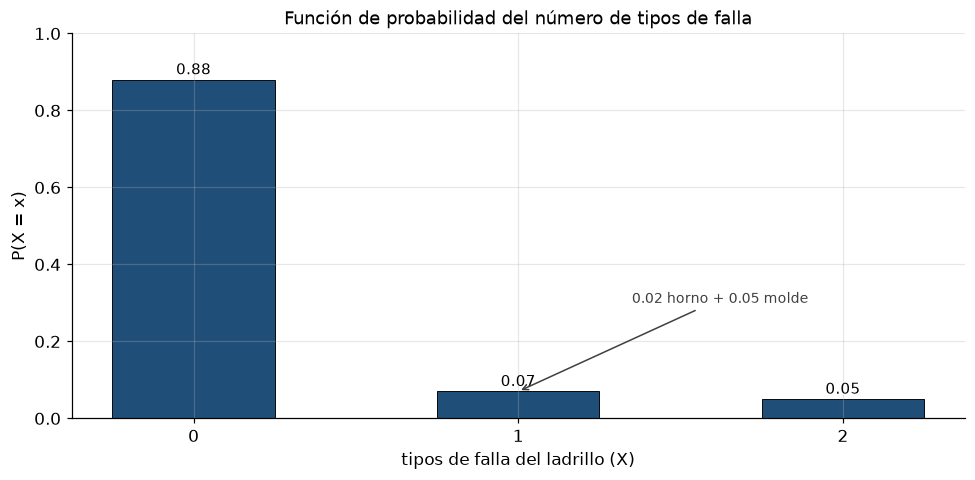

In [7]:
x2 = np.array(sorted(pmf2))
p2 = np.array([pmf2[x] for x in x2])

fig, ax = plt.subplots()
ax.bar(x2, p2, width=0.5, color=AZUL, edgecolor="black", linewidth=0.6)
for x, v in zip(x2, p2):
    ax.text(x, v + 0.014, f"{v:.2f}", ha="center", fontsize=10)
ax.annotate("0.02 horno + 0.05 molde", xy=(1, 0.07), xytext=(1.35, 0.30),
            fontsize=9, color="#404040",
            arrowprops=dict(arrowstyle="->", color="#404040", linewidth=1))
ax.set_xticks(x2)
ax.set_xlabel("tipos de falla del ladrillo (X)")
ax.set_ylabel("P(X = x)")
ax.set_ylim(0, 1.0)
ax.set_title("Función de probabilidad del número de tipos de falla")
plt.tight_layout()
plt.show()

## 3. Averías mensuales de una máquina y costo de reparación

Distribución dada, con dominio $D_X = \{0, 1, 2, 3, 4\}$:

| Averías $x$ | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $p(x)$ | 0.10 | 0.26 | 0.42 | 0.16 | 0.06 |

Se verifica $p(x) \ge 0$ y $\sum p(x) = 1.00$, de modo que es una función de probabilidad válida.

### a) Esperanza y varianza del número de averías

$$E[X] = \sum x\, p(x) = 0(0.10) + 1(0.26) + 2(0.42) + 3(0.16) + 4(0.06) = 1.82$$

$$E[X^2] = \sum x^2 p(x) = 0 + 0.26 + 1.68 + 1.44 + 0.96 = 4.34$$

$$Var(X) = E[X^2] - (E[X])^2 = 4.34 - 1.82^2 = 4.34 - 3.3124 = 1.0276$$

$$\sigma_X = \sqrt{1.0276} \approx 1.0137 \ \text{averías}$$

### b) Esperanza y desvío estándar del costo

El costo mensual es $C = 400 + 1500\,X$ (fijo más un monto por avería). Aplicando las propiedades
de la esperanza y de la varianza:

$$E[C] = 400 + 1500\,E[X] = 400 + 1500(1.82) = 3130$$

$$Var(C) = 1500^2\,Var(X) = 2\,250\,000 \cdot 1.0276 = 2\,312\,100$$

$$\sigma_C = 1500\,\sigma_X \approx 1520.56$$

El desplazamiento fijo de 400 no afecta el desvío; el desvío del costo se escala por el mismo
coeficiente 1500 que la esperanza.

Supuestos: la tabla es una función de probabilidad válida, el costo es lineal en $X$ con
coeficientes constantes (fijo y tarifa por avería no dependen del mes) y la reparación de cada
avería se pricea de igual forma.

In [8]:
x3 = np.array([0, 1, 2, 3, 4])
p3 = np.array([0.10, 0.26, 0.42, 0.16, 0.06])

E3 = (x3 * p3).sum()
E23 = (x3 ** 2 * p3).sum()
Var3 = E23 - E3 ** 2
sd3 = math.sqrt(Var3)

costos = 400 + 1500 * x3
E_costo = (costos * p3).sum()
Var_costo = 1500 ** 2 * Var3
sd_costo = math.sqrt(Var_costo)

print("suma p(x):", round(p3.sum(), 12))
print(f"E[X]   = {E3:.4f}")
print(f"E[X^2] = {E23:.4f}")
print(f"Var(X) = {Var3:.4f}   sigma = {sd3:.4f}")
print()
print(f"E[C]   = {E_costo:.2f}   (400 + 1500*E[X] = {400 + 1500 * E3:.2f})")
print(f"Var(C) = {Var_costo:.2f}")
print(f"sigma_C = {sd_costo:.4f}   (1500*sigma = {1500 * sd3:.4f})")

suma p(x): 1.0
E[X]   = 1.8200
E[X^2] = 4.3400
Var(X) = 1.0276   sigma = 1.0137

E[C]   = 3130.00   (400 + 1500*E[X] = 3130.00)
Var(C) = 2312100.00
sigma_C = 1520.5591   (1500*sigma = 1520.5591)


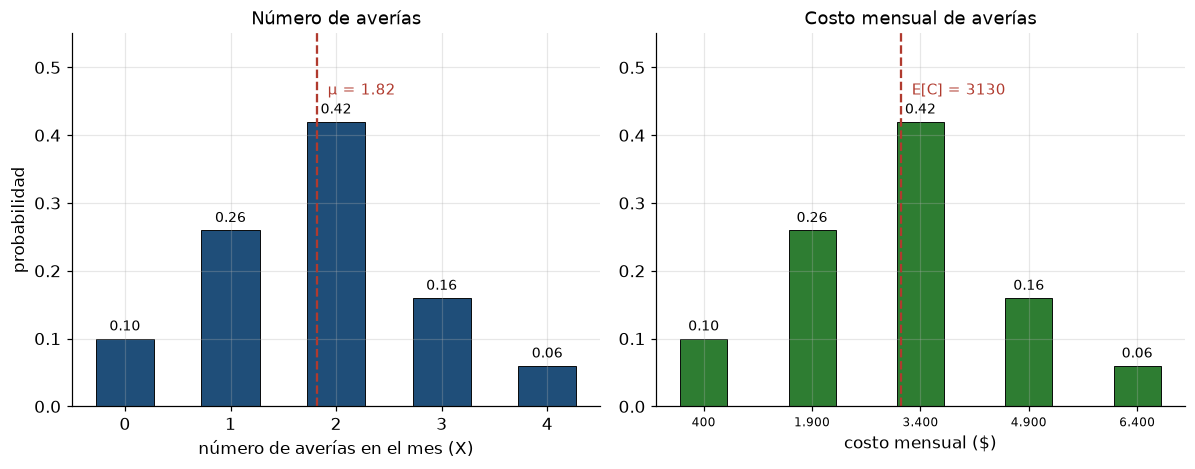

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

axs[0].bar(x3, p3, width=0.55, color=AZUL, edgecolor="black", linewidth=0.6)
for x, v in zip(x3, p3):
    axs[0].text(x, v + 0.012, f"{v:.2f}", ha="center", fontsize=9)
axs[0].axvline(E3, color=ROJO, linestyle="--", linewidth=1.5)
axs[0].text(E3 + 0.1, 0.46, f"μ = {E3:.2f}", color=ROJO, fontsize=10)
axs[0].set_xticks(x3)
axs[0].set_xlabel("número de averías en el mes (X)")
axs[0].set_ylabel("probabilidad")
axs[0].set_ylim(0, 0.55)
axs[0].set_title("Número de averías")

axs[1].bar(costos, p3, width=650, color=VERDE, edgecolor="black", linewidth=0.6)
for c, v in zip(costos, p3):
    axs[1].text(c, v + 0.012, f"{v:.2f}", ha="center", fontsize=9)
axs[1].axvline(E_costo, color=ROJO, linestyle="--", linewidth=1.5)
axs[1].text(E_costo + 150, 0.46, f"E[C] = {E_costo:.0f}", color=ROJO, fontsize=10)
axs[1].set_xticks(costos)
axs[1].set_xticklabels([f"{c:,}".replace(",", ".") for c in costos], fontsize=8)
axs[1].set_xlabel("costo mensual ($)")
axs[1].set_ylim(0, 0.55)
axs[1].set_title("Costo mensual de averías")

plt.tight_layout()
plt.show()

## 4. Kilometraje diario de una flota de remis por Chebyshev

Se conoce $\mu = 300$ km y $\sigma = 45$ km, sin conocer la distribución de probabilidad. Se pide
el intervalo que contiene al menos el 75% de los valores. De la forma complementaria del teorema de
Chebyshev:

$$P(|X - \mu| < k\sigma) \ge 1 - \frac{1}{k^2} = 0.75 \quad \Rightarrow \quad \frac{1}{k^2} = 0.25 \quad \Rightarrow \quad k = 2$$

El intervalo es

$$\mu \pm 2\sigma = 300 \pm 2(45) = [210,\ 390] \ \text{km}$$

Al menos el 75% de los kilometrajes diarios cae entre 210 y 390 km; el porcentaje real puede ser
mayor, porque Chebyshev da un mínimo garantizado.

Supuestos: media y desvío finitos y conocidos, varianza positiva, distribución desconocida (la
desigualdad no requiere suponer forma) y cota sobre la proporción dentro del intervalo abierto
$\mu \pm k\sigma$.

In [10]:
mu4, sigma4 = 300.0, 45.0

k4 = 1 / math.sqrt(1 - 0.75)
inferior = mu4 - k4 * sigma4
superior = mu4 + k4 * sigma4

print(f"k = {k4:.4f}")
print(f"intervalo = [{inferior:.1f}, {superior:.1f}] km")
print(f"garantía 1 - 1/k^2 = {1 - 1 / k4**2:.4f}")
print(f"verificación: mu ± 2*sigma = {mu4 - 2 * sigma4:.1f}, {mu4 + 2 * sigma4:.1f}")

k = 2.0000
intervalo = [210.0, 390.0] km
garantía 1 - 1/k^2 = 0.7500
verificación: mu ± 2*sigma = 210.0, 390.0


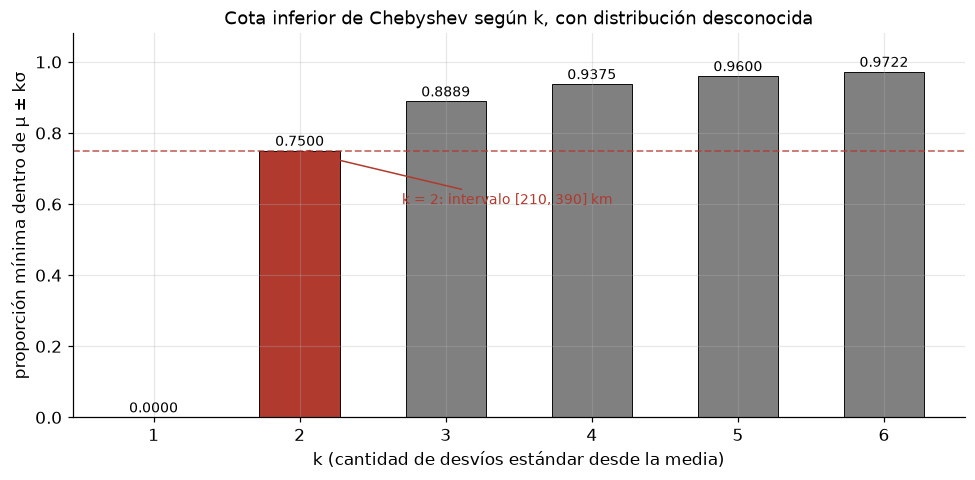

In [11]:
k_vals = np.arange(1, 7)
garantia = 1 - 1 / k_vals ** 2

fig, ax = plt.subplots()
colores = [ROJO if k == 2 else GRIS for k in k_vals]
ax.bar(k_vals, garantia, width=0.55, color=colores, edgecolor="black", linewidth=0.6)
for k, g in zip(k_vals, garantia):
    ax.text(k, g + 0.014, f"{g:.4f}", ha="center", fontsize=9)
ax.axhline(0.75, color=ROJO, linestyle="--", linewidth=1.2, alpha=0.7)
ax.annotate("k = 2: intervalo [210, 390] km", xy=(2, 0.75), xytext=(2.7, 0.60),
            fontsize=9, color=ROJO,
            arrowprops=dict(arrowstyle="->", color=ROJO, linewidth=1))
ax.set_xticks(k_vals)
ax.set_xlabel("k (cantidad de desvíos estándar desde la media)")
ax.set_ylabel("proporción mínima dentro de μ ± kσ")
ax.set_ylim(0, 1.08)
ax.set_title("Cota inferior de Chebyshev según k, con distribución desconocida")
plt.tight_layout()
plt.show()

## 5. Acotaciones con Chebyshev para $E[X] = 10$ y $Var(X) = 4$

La varianza 4 da $\sigma = 2$; la media es $\mu = 10$.

### a) $P(|X - 10| \ge 3)$

La desviación 3 corresponde a $k = 3/\sigma = 3/2 = 1.5$, de modo que

$$P(|X - 10| \ge 3) \le \frac{1}{k^2} = \frac{1}{1.5^2} = \frac{4}{9} \approx 0.4444$$

### b) $P(5 < X < 15)$

El intervalo es $|X - 10| < 5$, con $k = 5/\sigma = 2.5$:

$$P(5 < X < 15) \ge 1 - \frac{1}{2.5^2} = 1 - 0.16 = 0.84$$

### c) $P(|X - 10| \ge C) < 0.04$

Se exige $1/k^2 \le 0.04$, es decir $k^2 \ge 25$ y $k \ge 5$, con $C = k\sigma$:

$$C = 5 \cdot 2 = 10$$

Con $C = 10$ la cota de Chebyshev vale exactamente 0.04; si se mantiene la desigualdad estricta
del enunciado, cualquier $C > 10$ la cumple. El valor mínimo de trabajo es $C = 10$.

Supuestos: varianza finita y positiva ($\sigma = 2$), distribución desconocida y no impuesta; los
resultados son cotas, no probabilidades exactas: la desigualdad acota desde arriba en a) y c), y
desde abajo en b).

In [12]:
mu5, var5 = 10.0, 4.0
sd5 = math.sqrt(var5)

k_a = 3 / sd5
cota_a = 1 / k_a ** 2

k_b = 5 / sd5
cota_b = 1 - 1 / k_b ** 2

k_c = math.sqrt(1 / 0.04)
C = k_c * sd5

print(f"sigma = {sd5}")
print(f"a) k = {k_a}  ->  P(|X-10| >= 3) <= {cota_a:.4f}")
print(f"b) k = {k_b}  ->  P(5 < X < 15) >= {cota_b:.4f}")
print(f"c) k = {k_c}  ->  C = k*sigma = {C}  (cota {1 / k_c**2:.4f})")

sigma = 2.0
a) k = 1.5  ->  P(|X-10| >= 3) <= 0.4444
b) k = 2.5  ->  P(5 < X < 15) >= 0.8400
c) k = 5.0  ->  C = k*sigma = 10.0  (cota 0.0400)


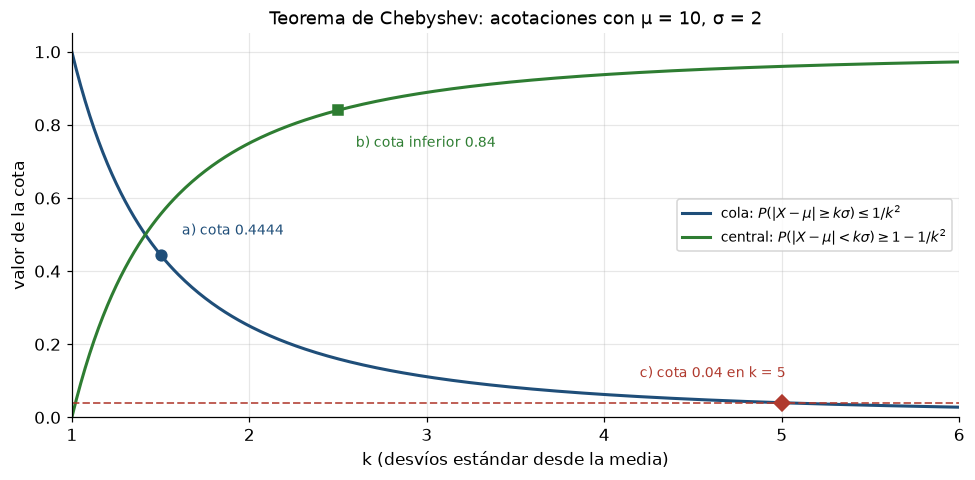

In [13]:
k = np.linspace(1, 6, 400)
cola = 1 / k ** 2
central = 1 - 1 / k ** 2

fig, ax = plt.subplots()
ax.plot(k, cola, color=AZUL, linewidth=2,
        label=r"cola: $P(|X-\mu| \geq k\sigma) \leq 1/k^2$")
ax.plot(k, central, color=VERDE, linewidth=2,
        label=r"central: $P(|X-\mu| < k\sigma) \geq 1 - 1/k^2$")
ax.axhline(0.04, color=ROJO, linestyle="--", linewidth=1.3, alpha=0.8)

ax.plot(1.5, 4 / 9, "o", color=AZUL, markersize=7)
ax.text(1.62, 0.50, "a) cota 0.4444", fontsize=9, color=AZUL)
ax.plot(2.5, 0.84, "s", color=VERDE, markersize=7)
ax.text(2.6, 0.74, "b) cota inferior 0.84", fontsize=9, color=VERDE)
ax.plot(5, 0.04, "D", color=ROJO, markersize=7)
ax.text(4.2, 0.11, "c) cota 0.04 en k = 5", fontsize=9, color=ROJO)

ax.set_xlabel("k (desvíos estándar desde la media)")
ax.set_ylabel("valor de la cota")
ax.set_xlim(1, 6)
ax.set_ylim(0, 1.05)
ax.set_title("Teorema de Chebyshev: acotaciones con μ = 10, σ = 2")
ax.legend(fontsize=9, loc="center right")
plt.tight_layout()
plt.show()

## 6. Densidad $f(x) = K(x - 2)$ en $[2, 4]$

$$f(x) = \begin{cases} K(x - 2) & 2 \le x \le 4 \\ 0 & x < 2,\ x > 4 \end{cases}$$

### a) Constante $K$

Por la condición de normalización, $f(x) \ge 0$ en el soporte y la integral total vale 1:

$$\int_2^4 K(x - 2)\,dx = K\left[\frac{(x-2)^2}{2}\right]_2^4 = K\left(\frac{4}{2} - 0\right) = 2K = 1 \quad \Rightarrow \quad K = \frac{1}{2} = 0.5$$

Con $K > 0$ la densidad es no negativa en todo el soporte, cumpliéndose también esa condición.

### b) Función de distribución acumulativa

$$F(x) = \int_{-\infty}^{x} f(t)\,dt = \begin{cases} 0 & x < 2 \\[4pt] \displaystyle\int_2^x \frac{1}{2}(t - 2)\,dt = \frac{(x-2)^2}{4} & 2 \le x \le 4 \\[4pt] 1 & x > 4 \end{cases}$$

Es monótona no decreciente y pasa de 0 a 1 sin saltos, como corresponde a una continua.

### c) Esperanza y varianza

$$E[X] = \int_2^4 x \cdot \frac{1}{2}(x - 2)\,dx = \frac{1}{2}\left[\frac{x^3}{3} - x^2\right]_2^4 = \frac{1}{2}\left[\frac{20}{3}\right] = \frac{10}{3} \approx 3.3333$$

$$E[X^2] = \int_2^4 x^2 \cdot \frac{1}{2}(x - 2)\,dx = \frac{1}{2}\left[\frac{x^4}{4} - \frac{2x^3}{3}\right]_2^4 = \frac{1}{2}\left[\frac{68}{3}\right] = \frac{34}{3} \approx 11.3333$$

$$Var(X) = \frac{34}{3} - \left(\frac{10}{3}\right)^2 = \frac{102 - 100}{9} = \frac{2}{9} \approx 0.2222, \qquad \sigma = \frac{\sqrt{2}}{3} \approx 0.4714$$

### d) Probabilidades

$$P(2.2 \le X \le 3) = F(3) - F(2.2) = \frac{1^2 - 0.2^2}{4} = \frac{0.96}{4} = 0.24$$

$$P(X \ge 3.5) = 1 - F(3.5) = 1 - \frac{1.5^2}{4} = 1 - 0.5625 = 0.4375$$

Supuestos: $f$ es una densidad válida (no negativa y con integral 1), $X$ es continua de modo que
$P(X = c) = 0$ para todo $c$, y en el soporte la densidad crece linealmente con $x$ (los valores
altos son más probables).

In [14]:
K6 = 0.5


def F6(x):
    """Función de acumulativa derivada en el ítem b)."""
    if x < 2:
        return 0.0
    if x > 4:
        return 1.0
    return (x - 2) ** 2 / 4


# verificación numérica por cuadratura
xs = np.linspace(2, 4, 40001)
fx = K6 * (xs - 2)

norm = np.trapezoid(fx, xs)
media = np.trapezoid(xs * fx, xs)
segundo = np.trapezoid(xs ** 2 * fx, xs)
varianza = segundo - media ** 2

p_1 = F6(3) - F6(2.2)
p_2 = 1 - F6(3.5)

print(f"a) K = 1/2 = {K6}")
print(f"integral de f (cuadratura) = {norm:.6f}")
print(f"b) F(2) = {F6(2):.4f}  F(3) = {F6(3):.4f}  F(4) = {F6(4):.4f}")
print(f"c) E[X]  analitica {10/3:.6f} | cuadratura {media:.6f}")
print(f"    E[X^2] analitica {34/3:.6f} | cuadratura {segundo:.6f}")
print(f"    Var(X) analitica {2/9:.6f} | cuadratura {varianza:.6f}")
print(f"d) P(2.2 <= X <= 3) = {p_1:.6f}")
print(f"    P(X >= 3.5)      = {p_2:.6f}")

a) K = 1/2 = 0.5
integral de f (cuadratura) = 1.000000
b) F(2) = 0.0000  F(3) = 0.2500  F(4) = 1.0000
c) E[X]  analitica 3.333333 | cuadratura 3.333333
    E[X^2] analitica 11.333333 | cuadratura 11.333333
    Var(X) analitica 0.222222 | cuadratura 0.222222
d) P(2.2 <= X <= 3) = 0.240000
    P(X >= 3.5)      = 0.437500


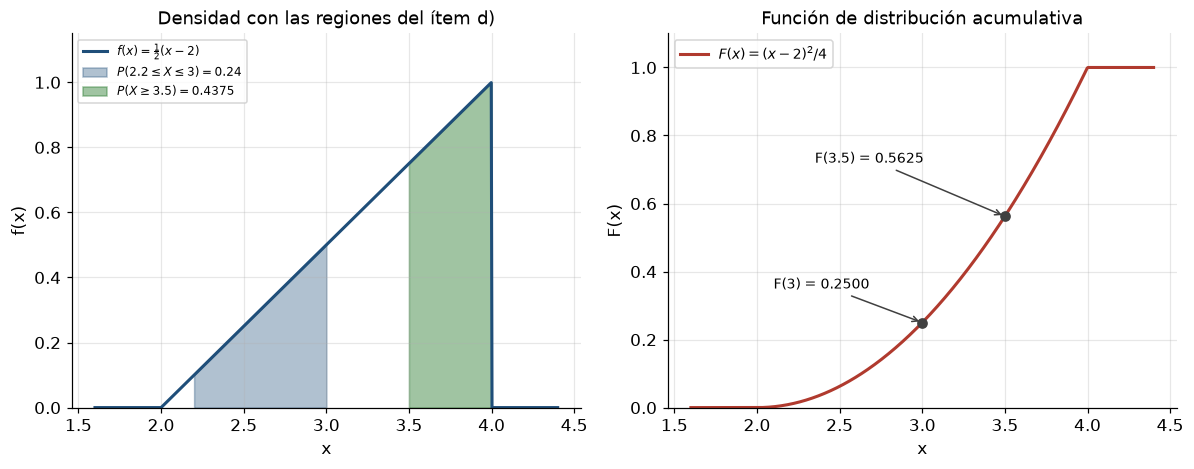

In [15]:
xg = np.linspace(1.6, 4.4, 600)
fg = np.where((xg >= 2) & (xg <= 4), K6 * (xg - 2), 0.0)
Fg = np.where(xg < 2, 0.0, np.where(xg > 4, 1.0, (xg - 2) ** 2 / 4))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

axs[0].plot(xg, fg, color=AZUL, linewidth=2, label=r"$f(x) = \frac{1}{2}(x-2)$")
x1 = np.linspace(2.2, 3, 300)
x2 = np.linspace(3.5, 4, 200)
axs[0].fill_between(x1, 0.5 * (x1 - 2), color=AZUL, alpha=0.35,
                    label=r"$P(2.2 \leq X \leq 3) = 0.24$")
axs[0].fill_between(x2, 0.5 * (x2 - 2), color=VERDE, alpha=0.45,
                    label=r"$P(X \geq 3.5) = 0.4375$")
axs[0].set_xlabel("x")
axs[0].set_ylabel("f(x)")
axs[0].set_ylim(0, 1.15)
axs[0].set_title("Densidad con las regiones del ítem d)")
axs[0].legend(fontsize=8, loc="upper left")

axs[1].plot(xg, Fg, color=ROJO, linewidth=2, label=r"$F(x) = (x-2)^2/4$")
axs[1].plot([3, 3.5], [F6(3), F6(3.5)], "o", color="#404040", markersize=6)
axs[1].annotate(f"F(3) = {F6(3):.4f}", xy=(3, F6(3)), xytext=(2.1, 0.35),
                fontsize=9, arrowprops=dict(arrowstyle="->", color="#404040", linewidth=1))
axs[1].annotate(f"F(3.5) = {F6(3.5):.4f}", xy=(3.5, F6(3.5)), xytext=(2.35, 0.72),
                fontsize=9, arrowprops=dict(arrowstyle="->", color="#404040", linewidth=1))
axs[1].set_xlabel("x")
axs[1].set_ylabel("F(x)")
axs[1].set_ylim(0, 1.1)
axs[1].set_title("Función de distribución acumulativa")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()

## 7. Esperanza y varianza a partir de la función de acumulada

$$F(x) = \begin{cases} 0 & x < 0 \\[4pt] \displaystyle\frac{x^3}{27} & 0 \le x \le 3 \\[4pt] 1 & x > 3 \end{cases}$$

$F$ es continua en todo $\mathbb{R}$ (en $x = 0$ y $x = 3$ las ramas coinciden con 0 y 1), no
decreciente y con límites correctos, por lo que corresponde a una variable continua. La densidad es
la derivada:

$$f(x) = F'(x) = \frac{x^2}{9}, \qquad 0 \le x \le 3, \qquad f(x) = 0 \ \text{en otro caso}$$

Verificación de normalización:

$$\int_0^3 \frac{x^2}{9}\,dx = \left[\frac{x^3}{27}\right]_0^3 = \frac{27}{27} = 1$$

### Esperanza

$$E[X] = \int_0^3 x \cdot \frac{x^2}{9}\,dx = \left[\frac{x^4}{36}\right]_0^3 = \frac{81}{36} = \frac{9}{4} = 2.25$$

### Varianza

$$E[X^2] = \int_0^3 x^2 \cdot \frac{x^2}{9}\,dx = \left[\frac{x^5}{45}\right]_0^3 = \frac{243}{45} = \frac{27}{5} = 5.4$$

$$Var(X) = E[X^2] - (E[X])^2 = 5.4 - 2.25^2 = 5.4 - 5.0625 = 0.3375$$

$$\sigma = \sqrt{0.3375} \approx 0.5809$$

Supuestos: $F$ continua y monótona no decreciente con valores extremos 0 y 1, diferenciable en el
interior del soporte (de donde se obtiene $f$), y $X$ continua con soporte $[0, 3]$; la densidad es
creciente, de modo que la media supera al punto medio del soporte.

In [16]:
# f(x) = F'(x) = x^2/9 en [0, 3]
xs7 = np.linspace(0, 3, 6001)
f7 = xs7 ** 2 / 9
F7 = xs7 ** 3 / 27

norma = np.trapezoid(f7, xs7)
media7 = np.trapezoid(xs7 * f7, xs7)
segundo7 = np.trapezoid(xs7 ** 2 * f7, xs7)
var7 = segundo7 - media7 ** 2

print(f"normalización (cuadratura) = {norma:.6f}   | F(3) = {F7[-1]:.6f}")
print(f"E[X]  analitica 2.250000 | cuadratura {media7:.6f}")
print(f"E[X^2] analitica 5.400000 | cuadratura {segundo7:.6f}")
print(f"Var(X) analitica 0.337500 | cuadratura {var7:.6f}")
print(f"sigma = {math.sqrt(var7):.4f}")

normalización (cuadratura) = 1.000000   | F(3) = 1.000000
E[X]  analitica 2.250000 | cuadratura 2.250000
E[X^2] analitica 5.400000 | cuadratura 5.400000
Var(X) analitica 0.337500 | cuadratura 0.337500
sigma = 0.5809


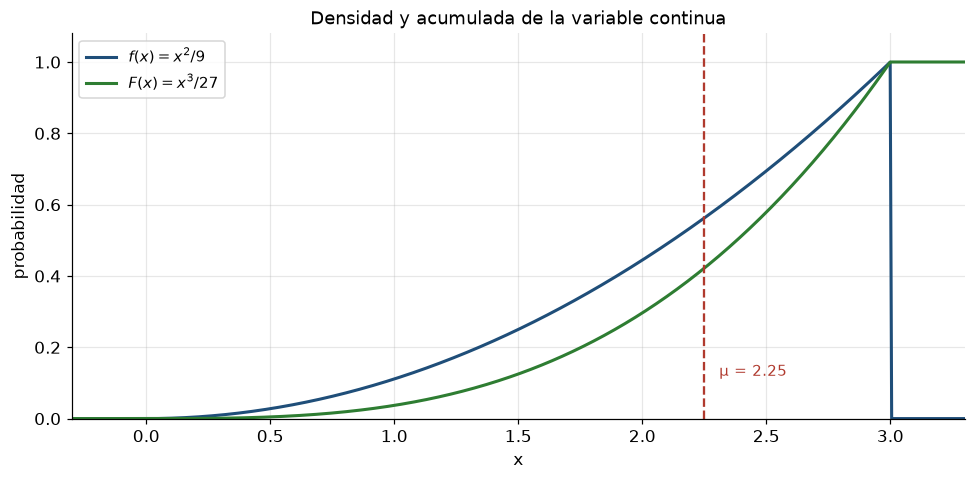

In [17]:
xg7 = np.linspace(-0.3, 3.3, 600)
fg7 = np.where((xg7 >= 0) & (xg7 <= 3), xg7 ** 2 / 9, 0.0)
Fg7 = np.where(xg7 < 0, 0.0, np.where(xg7 > 3, 1.0, xg7 ** 3 / 27))

fig, ax = plt.subplots()
ax.plot(xg7, fg7, color=AZUL, linewidth=2, label=r"$f(x) = x^2/9$")
ax.plot(xg7, Fg7, color=VERDE, linewidth=2, label=r"$F(x) = x^3/27$")
ax.axvline(2.25, color=ROJO, linestyle="--", linewidth=1.5)
ax.text(2.31, 0.12, "μ = 2.25", color=ROJO, fontsize=10)
ax.set_xlabel("x")
ax.set_ylabel("probabilidad")
ax.set_xlim(-0.3, 3.3)
ax.set_ylim(0, 1.08)
ax.set_title("Densidad y acumulada de la variable continua")
ax.legend(fontsize=10, loc="upper left")
plt.tight_layout()
plt.show()

## Notas de validación

- Las funciones de probabilidad de las secciones 1, 2 y 3 cumplen las dos condiciones del marco
  teórico: $p(x) \ge 0$ en todo el dominio y suma 1, comprobadas en la salida de cada celda.
- Las densidades de las secciones 6 y 7 cumplen $f(x) \ge 0$ e integral 1 sobre el soporte; la
  cuadratura numérica reproduce los valores analíticos de $K$, $E[X]$, $E[X^2]$ y $Var(X)$ dentro
  de la tolerancia del método.
- Propiedades aplicadas: $Var(X) = E[X^2] - (E[X])^2$ en las secciones 3, 6 y 7, y la linealidad de
  la esperanza junto con $Var(aX + b) = a^2 Var(X)$ para el costo de la sección 3 (el fijo 400 no
  modifica el desvío, el coeficiente 1500 lo escala).
- El teorema de Chebyshev (secciones 4 y 5) entrega cotas y no valores exactos, y no requiere
  conocer la distribución; solo exige varianza finita y positiva.
- La simulación Monte Carlo de la sección 1 usa semilla fija y converge a la función de probabilidad
  con un error del orden de $1/\sqrt{M}$, siendo $M$ el número de ensayos.

Referencias: Ross, S. - Probabilidad y estadística para ingeniería y ciencias. Meyer, P. -
Probabilidad y aplicaciones estadísticas. Walpole, R., Myers, R., Myers, S. - Probabilidad y
estadística para ingeniería y ciencias.